의사 결정 트리 분류

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

iris = load_iris()
X = iris.data[:, 2:] # petal length and width
y = iris.target

df = DecisionTreeClassifier(max_depth=3, random_state=42)
df.fit(X, y)

cscore=cross_val_score(df,X,y,cv=5)  # 교차 검증 k=5
print('accuracy',cscore.mean())
X.shape

accuracy 0.96


(150, 2)

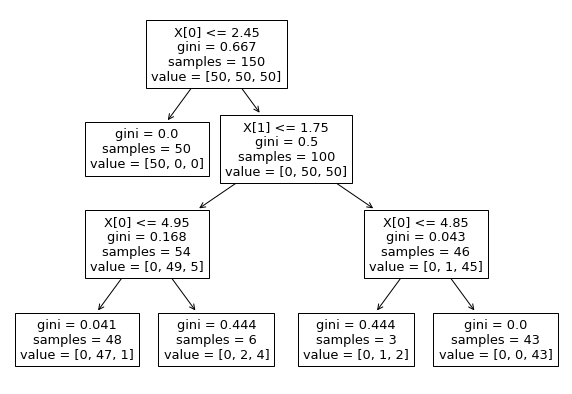

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(10,7))
plot_tree(df)
plt.show()

의사 결정 트리 회귀

In [ ]:
# 2차식으로 만든 데이터셋 + 잡음
import numpy as np
np.random.seed(42)
m = 200
X = np.random.rand(m, 1)
y = 4 * (X - 0.5) ** 2
y = y + np.random.randn(m, 1) / 10


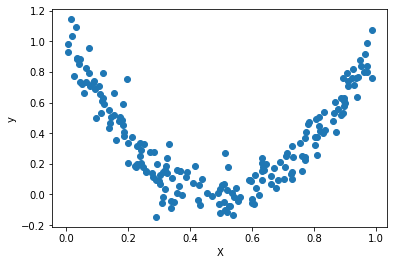

In [ ]:
plt.scatter(X,y)
plt.xlabel('X')
plt.ylabel('y')
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
y=y.squeeze() ##y가 1차원일때는 삭제
tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg.fit(X, y)
cscore=cross_val_score(tree_reg,X,y,cv=5,scoring='neg_mean_squared_error')
print('RMSE',np.sqrt(-cscore.mean()))


RMSE 0.1725409765371653
(200,)


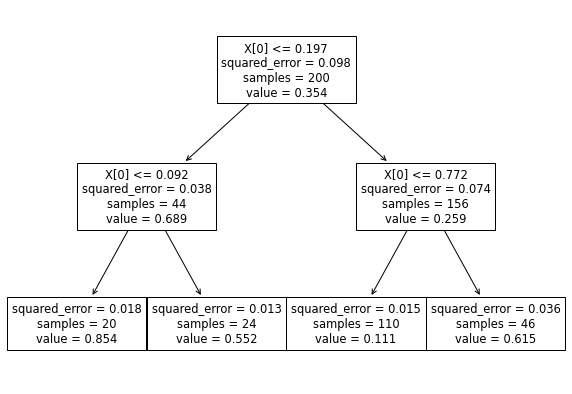

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(10,7))
plot_tree(tree_reg  )
plt.show()

랜덤 포레스트 분류

In [ ]:
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

iris = load_iris()
X = iris.data[:, 2:] # petal length and width
y = iris.target

df = RandomForestClassifier(n_estimators=30)
df.fit(X, y)

cscore=cross_val_score(df,X,y,cv=5)
print('accuracy',cscore.mean())
y.shape
#df.predict([[0.1,0.2]]) 새로운 입력에 대한 예측

accuracy 0.9666666666666668


(150,)

In [ ]:
# 2차식으로 만든 데이터셋 + 잡음
import numpy as np
np.random.seed(42)
m = 200
X = np.random.rand(m, 1)
y = 4 * (X - 0.5) ** 2
y = y + np.random.randn(m, 1) / 10


랜덤 포레스트 회귀

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
y=y.squeeze() #y가 1차원일때는 삭제
tree_reg = RandomForestRegressor(n_estimators=20)
tree_reg.fit(X, y)
cscore=cross_val_score(tree_reg,X,y,cv=5,scoring='neg_mean_squared_error')
print('RMSE',np.sqrt(-cscore.mean()))
X.shape
print(y.shape)

RMSE 0.11394871516737819
(200,)


의사 결정 나무 : grid search

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

iris = load_iris()
X = iris.data[:, 2:] # petal length and width
y = iris.target
params = {'max_depth': range(3, 10, 1),
          'min_samples_split': range(2, 10, 1)
          }
gs = GridSearchCV(DecisionTreeClassifier(random_state=42), params, n_jobs=-1)
gs.fit(X, y)
print(gs.best_params_)
print(gs.best_score_)


{'max_depth': 4, 'min_samples_split': 2}
0.9666666666666668
